In [1]:
#Librerias
import numpy as np #calculos numericos 
import matplotlib.pyplot as plt #graficos
from matplotlib import ticker #ajustar detalles en los ejes 
import math #para constantes matematicas y funciones
from netCDF4 import Dataset #para leer y extraer de archivos netcdf4 .nc

import warnings
warnings.filterwarnings("ignore")
%config InlineBackend.figure_format = 'retina'

In [2]:
# Constantes físicas
P0        = 1.0e5     # Presión base en Pa
R_earth   = 6360e3    # Radio terrestre en m
Gravity   = 9.806     # Aceleración de la gravedad en m/s²
R_gas     = 286.99    # Constante del gas ideal en J/kg.K
MW_dryair = 28.97     # Masa molecular del aire seco en g/mol
NA        = 6.022e23  # Número de Avogadro
deg2rad   = np.pi/180 # Conversión grados → radianes

def cargar_dataset(archivo):
    
    global data, lat, lon, hyam, hybm, hyai, hybi, temp, ps, tropp
    global nlat, nlon, nz, dlat, dlon
    global area, p, dp, dz, rho, volume
    global convertor, convertor2, convertor3
    global dataset_flag, molecules_cm3, rate_molec_cm3_s

    data = Dataset(archivo)

    # Coordenadas y coeficientes híbridos de presión
    lat  = data.variables['lat'][:].data
    lon  = data.variables['lon'][:].data
    hyam = data.variables['hyam'][:].data
    hybm = data.variables['hybm'][:].data
    hyai = data.variables['hyai'][:].data
    hybi = data.variables['hybi'][:].data

    # Variables meteorológicas básicas (primer paso de tiempo)
    temp  = data.variables['T'][:].data[0]
    ps    = data.variables['PS'][:].data[0]
    tropp = data.variables['TROP_P'][:].data[0]

    nlat = lat.shape[0]
    nlon = lon.shape[0]
    nz   = hyam.shape[0]

    dlat = lat[1] - lat[0]
    dlon = lon[1] - lon[0]

    # Cálculo de presión (p) y espesor de capas (dp)
    p = np.zeros([nz, nlat, nlon])
    for i in range(nz):
        p[i,:,:] = P0 * hyam[i] + hybm[i] * ps

    dp = np.zeros([nz, nlat, nlon])
    for i in range(nz):
        dp[i,:,:] = P0*(hyai[i+1] - hyai[i]) + (hybi[i+1] - hybi[i])*ps

    # Densidad del aire y espesor vertical (dz)
    rho = p / (R_gas * temp)
    dz = dp / (rho * Gravity)

    # Cálculo del área de las celdas de la grilla
    dlat_rad = dlat * deg2rad
    dlon_rad = dlon * deg2rad
    area = np.zeros([nlat, nlon])
    for j in range(nlat):
        lat1 = (lat[j] - dlat/2) * deg2rad
        lat2 = (lat[j] + dlat/2) * deg2rad
        area[j,:] = (R_earth**2) * dlon_rad * (np.sin(lat2) - np.sin(lat1))

    # Volumen de las celdas y factores de conversión
    volume = np.zeros([nz, nlat, nlon])
    for i in range(nz):
        volume[i,:,:] = dz[i,:,:] * area

    convertor = volume * 1e6
    convertor2 = area * NA * 1e3
    dz_surface = dz[0,:,:] 
    rate_molec_cm3_s = (NA) * 1e3 / (dz_surface * 1e6) 

    kB = 1.380649e-23  
    air_number_density = p / (kB * temp)   
    molecules_cm3 = air_number_density / 1e6 
    convertor3 = dp / Gravity

    dataset_flag = True

In [3]:
# Pesos atómicos
AW_Cl =  35.5
AW_Br =  79.9
AW_I  = 126.9
AW_H  =   1.0
AW_O  =  16.0
AW_N  =  14.0
AW_C  =  12.0
AW_F  =  19.0

# Pesos moleculares de especies halogenadas y sumideros
MW_O3      = 3 * AW_O
MW_CHBR3   = AW_C + AW_H + 3 * AW_Br
MW_CH2BR2  = AW_C + 2 * AW_H + 2 * AW_Br
MW_CH2BRCL = AW_C + 2 * AW_H + AW_Br + AW_Cl
MW_CHBR2CL = AW_C + AW_H + 2*AW_Br + AW_Cl
MW_CHBRCL2 = AW_C + AW_H + AW_Br + 2 * AW_Cl
MW_CH2IBR  = AW_C + 2 * AW_H + AW_I + AW_Br
MW_CH2ICL  = AW_C + 2 * AW_H + AW_I + AW_Cl
MW_CH3I    = AW_C + 3 * AW_H + AW_I
MW_CH2I2   = AW_C + 2 * AW_H + 2 * AW_I
MW_BR2     = 2* AW_Br
MW_BRCL    = AW_Br + AW_Cl
MW_BRNO2   = AW_Br + AW_N + 2*AW_O
MW_BRONO2  = AW_Br + AW_N + 3*AW_O
MW_CLNO2   = AW_Cl + AW_N + 2*AW_O
MW_CLONO2  = AW_Cl + AW_N + 3*AW_O
MW_HCL     = AW_H + AW_Cl
MW_HBR     = AW_H + AW_Br
MW_HI      = AW_H + AW_I
MW_HOBR    = AW_H + AW_O + AW_Br
MW_HOCL    = AW_H + AW_O + AW_Cl
MW_HOI     = AW_H + AW_O + AW_I
MW_IBR     = AW_I + AW_Br
MW_I2O2    = 2 * AW_I + 2 * AW_O
MW_I2O3    = 2 * AW_I + 3 * AW_O
MW_I2O4    = 2 * AW_I + 4 * AW_O
MW_ICL     = AW_I + AW_Cl
MW_CL2     = 2 * AW_Cl
MW_INO2    = AW_I + AW_N + 2*AW_O
MW_IONO2   = AW_I + AW_N + 3*AW_O
MW_I2      = 2*AW_I
MW_IO      = AW_I + AW_O
MW_OIO     = AW_I + 2*AW_O
MW_CH3BR   = AW_C + 3*AW_H + AW_Br
MW_CF3BR   = AW_C + 3*AW_F + AW_Br
MW_CF2CLBR = AW_C + 2*AW_F + AW_Cl + AW_Br
MW_CH3CL   = AW_C + 3*AW_H + AW_Cl
MW_CCL4    = AW_C + 4*AW_Cl  
MW_CH3CCL3 = 2*AW_C + 3*AW_H + 3*AW_Cl 
MW_CFCL3   = AW_C + AW_F + 3*AW_Cl
MW_CF2CL2  = AW_C + 2*AW_F + 2*AW_Cl
MW_CF2BR2  = AW_C + 2*AW_F + 2*AW_Br     
MW_C2F4BR2 = 2*AW_C + 4*AW_F + 2*AW_Br 
MW_CH2CL2  = AW_C + 2*AW_H + 2*AW_Cl
MW_CHCL3   = AW_C + AW_H + 3*AW_Cl
MW_C2CL4   = 2*AW_C + 4*AW_Cl
MW_C2H4CL2 = 2*AW_C + 4*AW_H + 2*AW_Cl
MW_CHCL2O2 = AW_C + AW_H + 2*AW_Cl + 2*AW_O
MW_COFCL   = AW_C + AW_O + AW_F + AW_Cl
MW_COCL2   = AW_C + AW_O + 2*AW_Cl

In [4]:
#Carga de variables
folder = "./" 
file = "FC.f19_f19_mg17.L32.cesm2.2-asdbranch_slh_released.FCnudged_slh.Historic_SLH.cam.h0.2020-00.nc"

cargar_dataset(folder + file)

# Extracción de variables de sumideros de Cloruros (Sinks)
dtwr_hcl    = data.variables["DTWR_HCL"][0]
dtwr_clno2  = data.variables["DTWR_CLNO2"][0]
dtwr_hocl   = data.variables["DTWR_HOCL"][0]
dtwr_clono2 = data.variables["DTWR_CLONO2"][0]
dtwr_brcl   = data.variables["DTWR_BRCL"][0]
dtwr_icl    = data.variables["DTWR_ICL"][0]

# Extracción de sumideros y flujos de Bromuros
dtwr_hobr   = data.variables["DTWR_HOBR"][0]
dtwr_hbr    = data.variables["DTWR_HBR"][0]
dtwr_brno2  = data.variables["DTWR_BRNO2"][0]
dtwr_brono2 = data.variables["DTWR_BRONO2"][0]
dtwr_br2    = data.variables["DTWR_BR2"][0]
dtwr_ibr    = data.variables["DTWR_IBR"][0]

md_hbr      = data.variables["DF_HBR"][0]
md_br2      = data.variables["DF_BR2"][0]
md_brno2    = data.variables["DF_BRNO2"][0]
md_brono2   = data.variables["DF_BRONO2"][0]
md_hobr     = data.variables["DF_HOBR"][0]

# Extracción de sumideros y flujos de Yoduros
dtwr_hi     = data.variables['DTWR_HI'][0]
dtwr_i2o2   = data.variables["DTWR_I2O2"][0]
dtwr_i2o3   = data.variables["DTWR_I2O3"][0]
dtwr_i2o4   = data.variables["DTWR_I2O4"][0]
dtwr_ino2   = data.variables["DTWR_INO2"][0]
dtwr_io     = data.variables["DTWR_IO"][0]
dtwr_iono2  = data.variables["DTWR_INO2"][0] 
dtwr_oio    = data.variables["DTWR_OIO"][0]

df_hi       = data.variables["DF_HI"][0]
df_hoi      = data.variables["DF_HOI"][0]
df_i2o2     = data.variables["DF_I2O2"][0]
df_i2o3     = data.variables["DF_I2O3"][0]
df_i2o4     = data.variables["DF_I2O4"][0]
df_ino2     = data.variables["DF_INO2"][0]
df_iono2    = data.variables["DF_IONO2"][0]


#Fra de yodo
r_ice_fr_brono2 = data.variables["r_ice_fr_brono2"][0]

# Carga de tasas de reacciones químicas y fotólisis específicas del modelo
fot_chbr3    = data.variables['r_jchbr3'][0]
fot_ch2br2   = data.variables['r_jch2br2'][0]
fot_ch2brcl  = data.variables['r_jch2brcl'][0]
fot_chbr2cl  = data.variables['r_jchbr2cl'][0]
fot_chbrcl2  = data.variables['r_jchbrcl2'][0]
fot_ch2ibr   = data.variables['r_jch2ibr'][0]
fot_h2402    = data.variables['r_jh2402'][0]
fot_ch3br    = data.variables['r_jch3br'][0]
fot_cf3br    = data.variables['r_jcf3br'][0]
fot_cf2clbr  = data.variables['r_jcf2clbr'][0]
fot_ch2icl  = data.variables["r_jch2icl"][0]
fot_ch2brcl = data.variables['r_jch2brcl'][0]
fot_chbr2cl = data.variables['r_jchbr2cl'][0]
fot_chbrcl2 = data.variables['r_jchbrcl2'][0]

oh_ch2brcl  = data.variables['r_CH2BRCL_OH'][0]
oh_chbr2cl  = data.variables['r_CHBR2CL_OH'][0] if 'r_CHBR2CL_OH' in data.variables else data.variables['r_CHBR2CL_OH'][0] # o la que corresponda en tu dataset
oh_chbrcl2  = data.variables['r_CHBRCL2_OH'][0]

oh_chbr3     = data.variables['r_CHBR3_OH'][0]
oh_ch2br2    = data.variables['r_CH2BR2_OH'][0]
oh_ch2brcl   = data.variables['r_CH2BRCL_OH'][0]
oh_chbr2cl   = data.variables['r_CH2BR2CL_OH'][0] if 'r_CH2BR2CL_OH' in data.variables else data.variables['r_CHBR2CL_OH'][0]
oh_chbrcl2   = data.variables['r_CHBRCL2_OH'][0]
oh_ch3br     = data.variables['r_CH3BR_OH'][0]

fot_ch2cl2   = data.variables["r_jch2cl2"][0]
fot_c2cl4    = data.variables["r_jc2cl4"][0]
fot_chcl3    = data.variables["r_jchcl3"][0]
fot_c2h4cl2  = data.variables["r_jc2h4cl2"][0]
fot_ch2i2    = data.variables["r_jch2i2"][0]
fot_ch2ibr   = data.variables["r_jch2ibr"][0]
fot_ch2icl   = data.variables["r_jch2icl"][0]
fot_ch3i     = data.variables["r_jch3i"][0]

oh_ch2cl2    = data.variables["r_CH2CL2_OH"][0]
oh_chcl3     = data.variables["r_CHCL3_OH"][0]
oh_c2cl4     = data.variables["r_C2CL4_OH"][0]
oh_c2h4cl2   = data.variables["r_C2H4CL2_OH"][0]

cl_ch2cl2    = data.variables["r_CH2CL2_CL"][0]
cl_chcl3     = data.variables["r_CHCL3_CL"][0]
cl_c2h4cl2   = data.variables["r_C2H4CL2_CL"][0]
cl_M_c2cl4   = data.variables["r_C2CL4_CL_M"][0]
o1d_chbr3    = data.variables['r_O1D_CHBR3'][0]
o1d_ch2br2   = data.variables['r_O1D_CH2BR2'][0]
cl_chbr3     = data.variables['r_CHBR3_CL'][0]
cl_ch2br2    = data.variables['r_CH2BR2_CL'][0]
cl_ch3br     = data.variables['r_CH3BR_CL'][0]
o1d_ch3br    = data.variables['r_O1D_CH3BR'][0]
o1d_cf2clbr  = data.variables['r_O1D_CF2CLBR'][0]
o1d_cf3br    = data.variables['r_O1D_CF3BR'][0]
o1d_h2402    = data.variables['r_O1D_H2402'][0]
brcl         = data.variables['BRCL'][0]

# Reacciones heterogéneas (SSA)
r_het_ss_0   = data.variables['r_het_ss_0'][0]
r_het_ss_1   = data.variables['r_het_ss_1'][0]
r_het_ss_2   = data.variables['r_het_ss_2'][0]
r_het_ss_3   = data.variables['r_het_ss_3'][0]
r_het_ss_4   = data.variables['r_het_ss_4'][0]
r_het_ss_5   = data.variables['r_het_ss_5'][0]
r_het_ss_6   = data.variables['r_het_ss_6'][0]
r_het_ss_7   = data.variables['r_het_ss_7'][0]
r_het_ss_8   = data.variables['r_het_ss_8'][0]
r_het_ss_12  = data.variables['r_het_ss_12'][0]
r_het_ss_9   = data.variables['r_het_ss_9'][0]

# Familias y especies de Cloro, Bromo e Yodo
broy         = data.variables['BROY'][0]
cloy         = data.variables['CLOY'][0]
ioy          = data.variables['IOY'][0]

cl           = data.variables["CL"][0]
clo          = data.variables["CLO"][0]
hcl          = data.variables["HCL"][0]
hocl         = data.variables["HOCL"][0]
clono2       = data.variables["CLONO2"][0]
clno2        = data.variables["CLNO2"][0]
cl2          = data.variables["CL2"][0]
cl2o2        = data.variables["CL2O2"][0]
oclo         = data.variables["OCLO"][0]
chcl2o2      = data.variables["CHCL2O2"][0]
oh_ch3i      = data.variables["r_CH3I_OH"][0]
cocl2        = data.variables["COCL2"][0]
cofcl        = data.variables["COFCL"][0]
cl_ch3i      = data.variables["r_CH3I_CL"][0]
br           = data.variables["BR"][0]
bro          = data.variables["BRO"][0]
hbr          = data.variables["HBR"][0]
hobr         = data.variables["HOBR"][0]
brono2       = data.variables["BRONO2"][0]
brno2        = data.variables["BRNO2"][0]
br2          = data.variables["BR2"][0]

i_           = data.variables["I"][0]
io           = data.variables["IO"][0]
hi           = data.variables["HI"][0]
hoi          = data.variables["HOI"][0]
iono2        = data.variables["IONO2"][0]
ino2         = data.variables["INO2"][0]
i2           = data.variables["I2"][0]
ibr          = data.variables["IBR"][0]  
icl          = data.variables["ICL"][0]
brcl         = data.variables["BRCL"][0]

cloy_sums    = data.variables["CLOy_sums"][0]
broy_sums    = data.variables["BROy_sums"][0]
ioy_sums     = data.variables["IOy_sums"][0]

ocean_hoi    = data.variables['SFHOI'][0]
emiss_i2     = data.variables['SFI2'][0]

# Pérdidas de Oxígeno Impar (OddOx)
OddOx_BROx_Loss     = data.variables["OddOx_BROx_Loss"][0]
OddOx_CLOxBROx_Loss = data.variables["OddOx_CLOxBROx_Loss"][0]
OddOx_CLOx_Loss     = data.variables["OddOx_CLOx_Loss"][0]
OddOx_HOx_Loss      = data.variables["OddOx_HOx_Loss"][0]
OddOx_IOx_Loss      = data.variables["OddOx_IOx_Loss"][0]
OddOx_Loss_Tot      = data.variables["OddOx_Loss_Tot"][0]
OddOx_NOx_Loss      = data.variables["OddOx_NOx_Loss"][0]
OddOx_Ox_Loss       = data.variables["OddOx_Ox_Loss"][0]
OddOx_Prod_Tot      = data.variables["OddOx_Prod_Tot"][0]

#IXOY para yodo
r_ss_ixoy_2  = data.variables["r_ss_ixoy_2"][0]
r_ss_ixoy_3  = data.variables["r_ss_ixoy_3"][0]
r_ss_ixoy_4  = data.variables["r_ss_ixoy_4"][0]

In [5]:
# Familias 
# Bromo (Br_y)
bryy =  br + bro + hbr + hobr + brono2 + brno2 + 2*br2 + brcl + ibr
br_vmr = [br*1e12, bro*1e12, hbr*1e12, hobr*1e12, brcl*1e12, (brno2 + brono2)*1e12, (ibr + br2)*1e12, bryy*1e12]

f_vsl = 3 * fot_chbr3 + 2 * fot_ch2br2 + fot_ch2brcl + 2 * fot_chbr2cl + fot_chbrcl2 + fot_ch2ibr 
oh_vsl = 3 * oh_chbr3 + 2 * oh_ch2br2 + oh_ch2brcl + 2 * oh_chbr2cl + oh_chbrcl2 
cl_vsl = 3 * cl_chbr3 + 2 * cl_ch2br2
o1d_vsl = 3 * o1d_chbr3 + 2 * o1d_ch2br2
vsl = f_vsl + oh_vsl + cl_vsl + o1d_vsl
f_ll =  2 * fot_h2402 + fot_cf3br + fot_cf2clbr  
o1d_ll = o1d_cf3br + o1d_cf2clbr 
ll = f_ll + o1d_ll
ll_ch3br = fot_ch3br + oh_ch3br + cl_ch3br + o1d_ch3br
h = 0.65 * (r_het_ss_0 + r_het_ss_1 + r_het_ss_2) + 0.5 * (r_het_ss_6 + r_het_ss_7 + r_het_ss_8)
c = [vsl, ll, ll_ch3br, h] 

# Cloro (Cl_y) 
clyy = cl + clo + hcl + hocl + clono2 + clno2 + 2*cl2 + 2*cl2o2 + oclo + brcl + icl
cl_vmr = [cl*1e12, clo*1e12, hcl*1e12, hocl*1e12, brcl*1e12, (clno2 + clono2)*1e12, (icl + cl2)*1e12, clyy*1e12]

cl_f_vsl_n = fot_ch2icl + fot_ch2brcl + fot_chbr2cl + 2 * fot_chbrcl2  
cl_oh_vsl_n =  oh_ch2brcl +  oh_chbr2cl + 2 * oh_chbrcl2 
cl_vsl_n = cl_oh_vsl_n + cl_f_vsl_n

cl_f_vsl_a = 2 * fot_ch2cl2 + 4*fot_c2cl4 + 3*fot_chcl3 + 2*fot_c2h4cl2
cl_oh_vsl_a = 2 * oh_ch2cl2 + 4*oh_c2cl4 + 3*oh_chcl3 + 2*oh_c2h4cl2
cl_cl_a = 2 * cl_ch2cl2  + 3*cl_chcl3 + 2*cl_c2h4cl2 + 4*cl_M_c2cl4
cl_vsl_a = cl_f_vsl_a + cl_oh_vsl_a + cl_cl_a

#  Yodo (I_y)
iyy = i_ + io + hi + hoi + iono2 + ino2 + 2*i2
i_vmr = [i_*1e12, io*1e12, hi*1e12, hoi*1e12, (ino2 + iono2)*1e12, (i2 + ibr + icl)*1e12, iyy*1e12]
i_f_vsl = fot_ch2icl + fot_ch2ibr + 2 * fot_ch2i2
i_vsl_ch3i = fot_ch3i + cl_ch3i + oh_ch3i
i_vsl = i_f_vsl 
ocean = (ocean_hoi*rate_molec_cm3_s*3e1 / MW_HOI) + (2*emiss_i2*rate_molec_cm3_s*3e1/ MW_I2)

In [6]:
# Cálculo de sumideros Cl_y, Br_y e I_y

# Cloruros (Cl_y)
dtwr_ress = -MW_dryair / 1e-12 * 86000 * (
    (1/MW_HCL) * dtwr_hcl + 
    (1/MW_CLNO2) * dtwr_clno2 + 
    (1/MW_HOCL) * dtwr_hocl + 
    (1/MW_CLONO2) * dtwr_clono2
)

#  Bromuros (Br_y) 
dtwr_res = -MW_dryair / 1e-12 * 86000 * (
    (1/MW_HOBR) * dtwr_hobr + 
    (1/MW_HBR) * dtwr_hbr + 
    (2/MW_BRNO2) * dtwr_brno2 + 
    (2/MW_BRONO2) * dtwr_brono2
)

# Deposición seca de bromo (superficie)
md = (
    (2 * md_br2 * Gravity / dp[0,:,:] / MW_BR2) +
    (md_hobr * Gravity / dp[0,:,:] / MW_HOBR) +
    (md_hbr * Gravity / dp[0,:,:] / MW_HBR) +
    (md_brno2 * Gravity / dp[0,:,:] / MW_BRNO2) +
    (md_brono2 * Gravity / dp[0,:,:] / MW_BRONO2)
)
md_pptv_day = md * MW_dryair * 1e12 * 86400  

# Yoduros (I_y)
dtwr_i_res = np.abs(-MW_dryair / 1e-12 * 86000 * (
    (1 / MW_HI) * dtwr_hi +
    (1 / MW_IONO2) * dtwr_iono2 +
    (1 / MW_INO2) * dtwr_ino2 +
    (1 / MW_IO) * dtwr_io +
    (1 / MW_OIO) * dtwr_oio +
    (2 / MW_I2O2) * dtwr_i2o2 +
    (2 / MW_I2O3) * dtwr_i2o3 +
    (2 / MW_I2O4) * dtwr_i2o4
))

md_i = (
    (df_hi * Gravity / dp[0,:,:] / MW_HI) +
    (df_hoi * Gravity / dp[0,:,:] / MW_HOI) +
    (2 * df_i2o2 * Gravity / dp[0,:,:] / MW_I2O2) +
    (2 * df_i2o3 * Gravity / dp[0,:,:] / MW_I2O3) +
    (2 * df_i2o4 * Gravity / dp[0,:,:] / MW_I2O4) +
    (df_ino2 * Gravity / dp[0,:,:] / MW_INO2) +
    (df_iono2 * Gravity / dp[0,:,:] / MW_IONO2)
)
md_i_pptv_day = md_i * MW_dryair * 1e12 * 86400

# Deposición Seca de Cloro
DF_HCL = data.variables["DF_HCL"][0]
DF_HOCL = data.variables["DF_HOCL"][0]
DF_CLONO2 = data.variables["DF_CLONO2"][0]
DF_CLNO2 = data.variables["DF_CLNO2"][0]
DF_COCL2 = data.variables["DF_COCL2"][0]

md_cl = (
    (DF_HCL * Gravity / dp[0,:,:] / MW_HCL) +
    (DF_HOCL * Gravity / dp[0,:,:] / MW_HOCL) +
    (DF_CLONO2 * Gravity / dp[0,:,:] / MW_CLONO2) +
    (DF_CLNO2 * Gravity / dp[0,:,:] / MW_CLNO2) +
    (DF_COCL2 * Gravity / dp[0,:,:] / MW_COCL2)
)
#dry deposition o mass deposition
md_cl_pptv_day = md_cl * MW_dryair * 1e12 * 86400

#  Tasas heterogéneas de yodo 
r_liq_fr_hoi = data.variables['r_liq_fr_hoi'][0]
r_ice_fr_hi = data.variables['r_ice_fr_hi'][0]
r_ice_fr_hoi = data.variables['r_ice_fr_hoi'][0]
r_ice_fr_iono2 = data.variables['r_ice_fr_iono2'][0]

seconds_per_month = 86400 * 30  

fra_i_tot = np.abs(
    r_liq_fr_hoi / molecules_cm3 + 
    r_ice_fr_hoi / molecules_cm3 + 
    r_ice_fr_hi / molecules_cm3 + 
    r_ice_fr_iono2 / molecules_cm3
) * 1e12 * seconds_per_month

#FRA de bromo

fra_br = (r_ice_fr_brono2 / molecules_cm3) * 1e12 * seconds_per_month

#IXOY para yodo

ixoy_yodo = (r_ss_ixoy_2 / molecules_cm3 + r_ss_ixoy_3 / molecules_cm3 + r_ss_ixoy_4 / molecules_cm3) * 1e12 * seconds_per_month

print("Mínimo md_cl:", np.nanmin(md_cl))
print("Máximo md_cl:", np.nanmin(md_cl))
print("Nuevo Mínimo fra_i_tot:", np.nanmin(fra_i_tot))
print("Nuevo Máximo fra_i_tot:", np.nanmax(fra_i_tot))
#'r_ice_fr_brono2' para los fra de bromo
#'r_ss_ixoy_2' son los IXOY para el yodo
#'r_ss_ixoy_3'
#'r_ss_ixoy_4'
#[v for v in data.variables.keys() if 'r_o' in v.lower()]


Mínimo md_cl: 1.9135183101307382e-18
Máximo md_cl: 1.9135183101307382e-18
Nuevo Mínimo fra_i_tot: 0.0
Nuevo Máximo fra_i_tot: 496.4527367703428


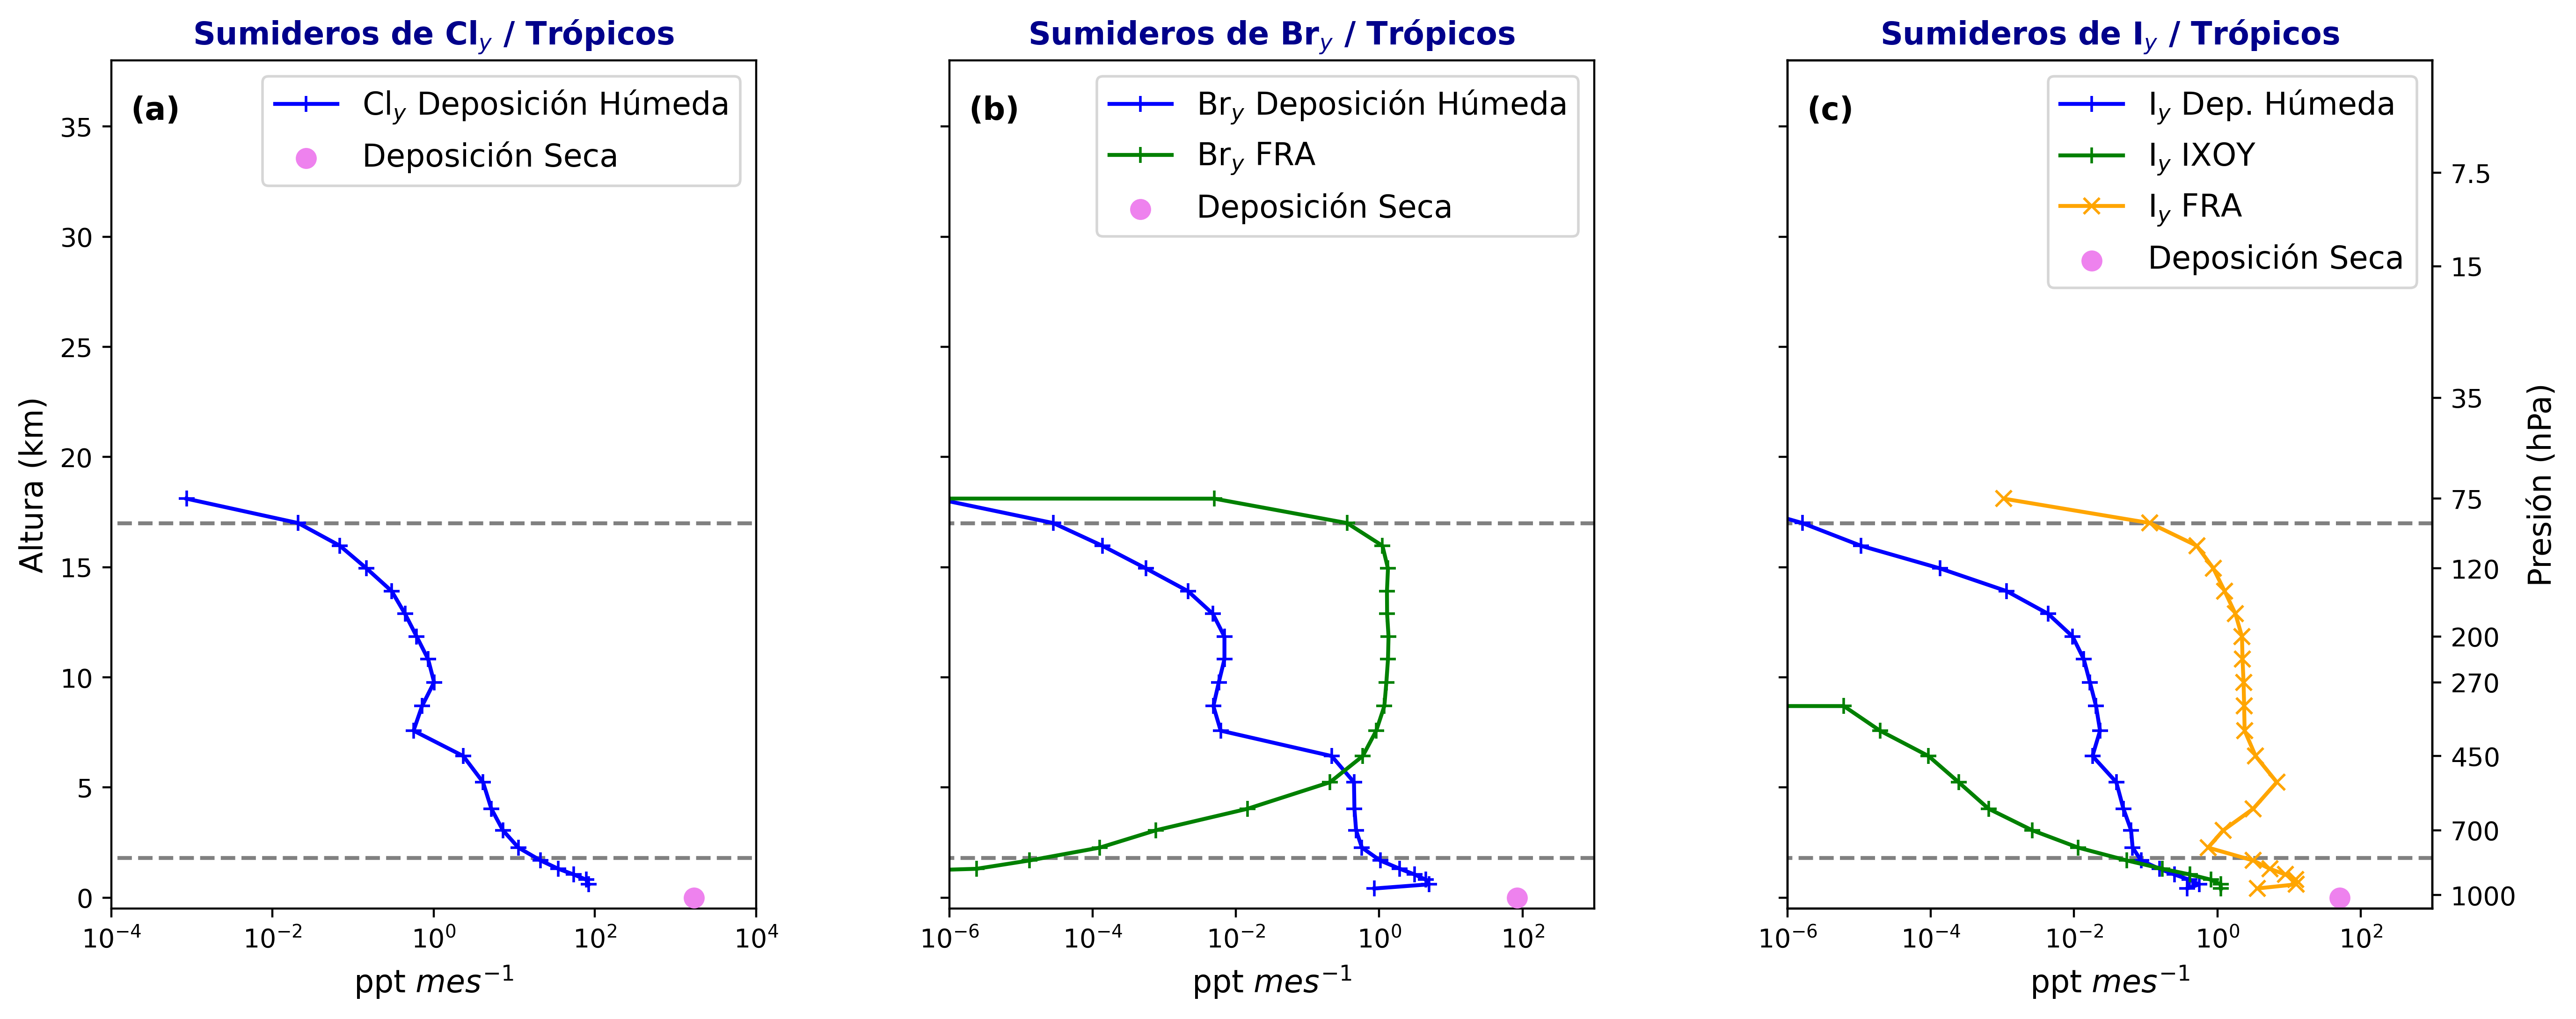

In [10]:
# Ploteo

# Coordenadas verticales de referencia (Altura en km y Presión en hPa)
H = [38.0217, 32.8987, 28.6571, 25.1301, 22.6889, 21.5085, 20.3665, 19.2606,
     18.1107, 17.0031, 15.9729, 14.942, 13.9116, 12.8814, 11.853, 10.826, 9.77737,   8.69542, 
     7.5791, 6.42741, 5.23926, 4.03541, 3.05838, 2.27118, 1.68529, 1.30937,  1.05048, 0.814904,
     0.603055, 0.415288, 0.251906, 0.113291]
    
Pre = [3.5, 7.5, 15, 25, 35, 45, 50, 60, 75, 90, 100, 120, 140, 170, 200, 230, 270, 320, 380, 450, 520, 610, 700, 770, 825, 865, 900, 920, 940, 960, 980, 1000]
positions = np.array([0, 1, 2, 4, 8, 11, 14, 16, 19, 22, 31]) 
alturag = [H[i] for i in positions]
presg = [Pre[i] for i in positions]

# Configuración de la figura
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True, dpi=200)
plt.subplots_adjust(wspace=0.3)

# Panel 1: Sumideros de Cl_y (Trópicos)
axes[0].plot(np.mean(dtwr_ress[:, 37:59, :], axis=(1,2))[8:29], H[8:29], label="Cl$_y$ Deposición Húmeda", color="blue", marker="+")
axes[0].scatter(np.nanmean(md_cl_pptv_day[37:59, :] if md_cl_pptv_day.ndim == 3 else md_cl_pptv_day), 0, color="violet", marker="o", s=50, zorder=10, label="Deposición Seca")
axes[0].set_xlim(1e-4, 1e4)
axes[0].set_title("Sumideros de Cl$_y$ / Trópicos", fontsize=12, fontweight='bold', color='darkblue')

# Panel 2: Sumideros de Br_y (Trópicos)
axes[1].plot(np.mean(dtwr_res[:, 37:59, :], axis=(1,2))[6:30], H[6:30], label="Br$_y$ Deposición Húmeda", color="blue", marker="+")
axes[1].plot(np.mean(fra_br[:, 37:59, :], axis=(1,2))[6:30], H[6:30], label="Br$_y$ FRA", color="green", marker="+")
axes[1].scatter(np.nanmean(md_pptv_day[37:59, :] if md_pptv_day.ndim == 3 else md_pptv_day), 0, color="violet", marker="o", s=50, zorder=10, label="Deposición Seca")
axes[1].set_xlim(1e-6, 1e3)
axes[1].set_title("Sumideros de Br$_y$ / Trópicos", fontsize=12, fontweight='bold', color='darkblue')

# Panel 3: Sumideros de I_y (Trópicos)
axes[2].plot(np.mean(dtwr_i_res[:, 37:59, :], axis=(1,2))[6:30], H[6:30], label="I$_y$ Dep. Húmeda", color="blue", marker="+")
fra_plottable = np.ma.masked_equal(np.mean(fra_i_tot[:, 37:59, :], axis=(1,2))[6:30], 0.0)
axes[2].plot(np.mean(ixoy_yodo[:, 37:59, :], axis=(1,2))[6:30], H[6:30], label="I$_y$ IXOY", color="green", marker="+")
axes[2].plot(fra_plottable, H[6:30], label="I$_y$ FRA", color="orange", marker="x")
axes[2].scatter(np.nanmean(md_i_pptv_day[37:59, :] if md_i_pptv_day.ndim == 3 else md_i_pptv_day), 0, color="violet", marker="o", s=50, zorder=10, label="Deposición Seca")
axes[2].set_xlim(1e-6, 1e3)
axes[2].set_title("Sumideros de I$_y$ / Trópicos", fontsize=12, fontweight='bold', color='darkblue')

# Configuraciones estéticas comunes de los ejes
for i, ax in enumerate(axes):
    ax.set_xscale("log")
    ax.set_ylim(-0.5, 38)
    ax.hlines(y=1.8, xmin=1e-7, xmax=1e4, ls="--", color='gray')
    ax.hlines(y=17, xmin=1e-7, xmax=1e4, ls="--", color='gray')  
    ax.set_xlabel(r'ppt $mes^{-1}$', fontsize=12)
    ax.legend(loc='upper right', fontsize=12)
    ax.text(0.03, 0.93, f'({chr(97+i)})', transform=ax.transAxes, fontsize=12, fontweight='bold')

axes[0].set_ylabel("Altura (km)", fontsize=12)

# Eje secundario de Presión (hPa) a la derecha
ax2 = axes[-1].twinx()
ax2.set_yticks(alturag)
ax2.set_yticklabels(presg)
ax2.set_ylim(-0.5, 38)
ax2.set_ylabel('Presión (hPa)', fontsize=12)

plt.show()